In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load cleaned dataset
df = pd.read_csv(
    r"C:\Users\konic\Business Dataset Analysis\outputs\indian_startup_funding_cleaned.csv"
)

# Convert date column
df["announced_date"] = pd.to_datetime(df["announced_date"])

# Display dataset information
print("EDA dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()


EDA dataset loaded successfully!
Dataset shape: (5006, 19)


,round_id,announced_date,year,company_name,company_domain,country,city,sector,founded_year,stage,amount_usd,amount_status,lead_investor,investor_count,news_mentions,news_source,news_url,news_excerpt,fliar_profile_url
0,ac8c7e0d61de,2015-01-04,2015,Flipkart,flipkart.com,India,Bengaluru,Retail,2007,Series B,340000000.0,verified,Dst Global,2,9,Unavailable,NaN,both Flipkart and Snapdeal roped in new marque...,https://fliarbi.com/company/flipkart/2i3fwhd10...
1,cf74029f78d9,2015-01-05,2015,Purplle,purplle.com,India,Mumbai,Retail,2012,Undisclosed,NaN,not_disclosed,Ivycap Ventures,1,17,Unavailable,NaN,Mumbai-based venture capital firm IvyCap Ventu...,https://fliarbi.com/company/purplle/1i5v22nmvv...
2,acdb7ec77d95,2015-01-08,2015,Bewakoof,bewakoof.com,India,Mumbai,Consumer,2011,Undisclosed,NaN,not_disclosed,Sixth Sense Ventures,5,9,Unavailable,NaN,"Bewakoof, an online apparel startup decides to...",https://fliarbi.com/company/bewakoof/efa24cfrs...
3,bb4b184702d5,2015-01-08,2015,Proof of Performance,proof-of-performance.com,India,New Delhi,Enterprise Applications,2010,Bridge,NaN,not_disclosed,Unknown,0,2,Unavailable,NaN,The company is also looking to raise some brid...,https://fliarbi.com/company/proof-of-performan...
4,ed276276204c,2015-01-09,2015,My Dream Store,mydreamstore.in,India,Hyderabad,Retail,2014,Undisclosed,216000.0,verified,few Private Investors,2,2,Unavailable,NaN,"Hyderabad-based online merchandise startup, My...",https://fliarbi.com/company/my-dream-store/3a6...


In [2]:

# Numerical summary
print("Numerical Summary:")
display(df.describe())

# Categorical summary
print("\nCategorical Summary:")
display(df.describe(include="object"))

# Unique values in important columns
print("\nUnique Companies:", df["company_name"].nunique())
print("Unique Cities:", df["city"].nunique())
print("Unique Sectors:", df["sector"].nunique())
print("Unique Investors:", df["lead_investor"].nunique())
print("Funding Stages:", df["stage"].nunique())


Numerical Summary:


,announced_date,year,founded_year,amount_usd,investor_count,news_mentions
count,5006,5006.000000,5006.000000,4.031000e+03,5006.000000,5006.000000
mean,2021-04-02 14:54:01.869756416,2020.751698,2015.362565,2.284983e+07,3.567918,5.089892
min,2015-01-04 00:00:00,2015.000000,2000.000000,4.000000e+02,0.000000,1.000000
25%,2018-12-13 18:00:00,2018.000000,2013.000000,1.000000e+06,1.000000,1.000000
50%,2021-09-15 00:00:00,2021.000000,2016.000000,4.000000e+06,2.000000,3.000000
75%,2023-09-13 00:00:00,2023.000000,2019.000000,1.500000e+07,5.000000,6.750000
max,2026-06-11 00:00:00,2026.000000,2024.000000,1.000000e+09,38.000000,148.000000
std,NaN,3.010350,4.516082,6.417970e+07,3.689346,6.362627



Categorical Summary:


,round_id,company_name,company_domain,country,city,sector,stage,amount_status,lead_investor,news_source,news_url,news_excerpt,fliar_profile_url
count,5006,5006,5006,5006,5006,5006,5006,5006,5006,5006,2888,5006,4993
unique,5006,2163,2163,1,128,49,24,4,1858,201,2643,4852,2160
top,ac8c7e0d61de,AYEFin,ayefin.com,India,Bengaluru,Consumer,Undisclosed,verified,Unknown,Unavailable,https://viestories.com/list-of-startups-funded...,Unavailable,https://fliarbi.com/company/ayefin/2qfqhq6lvc/...
freq,1,30,30,5006,1465,867,1656,3960,1004,2118,9,74,30



Unique Companies: 2163
Unique Cities: 128
Unique Sectors: 49
Unique Investors: 1858
Funding Stages: 24


    year  funding_rounds
0   2015             303
1   2016             282
2   2017             319
3   2018             366
4   2019             397
5   2020             427
6   2021             666
7   2022             637
8   2023             544
9   2024             543
10  2025             384
11  2026             138


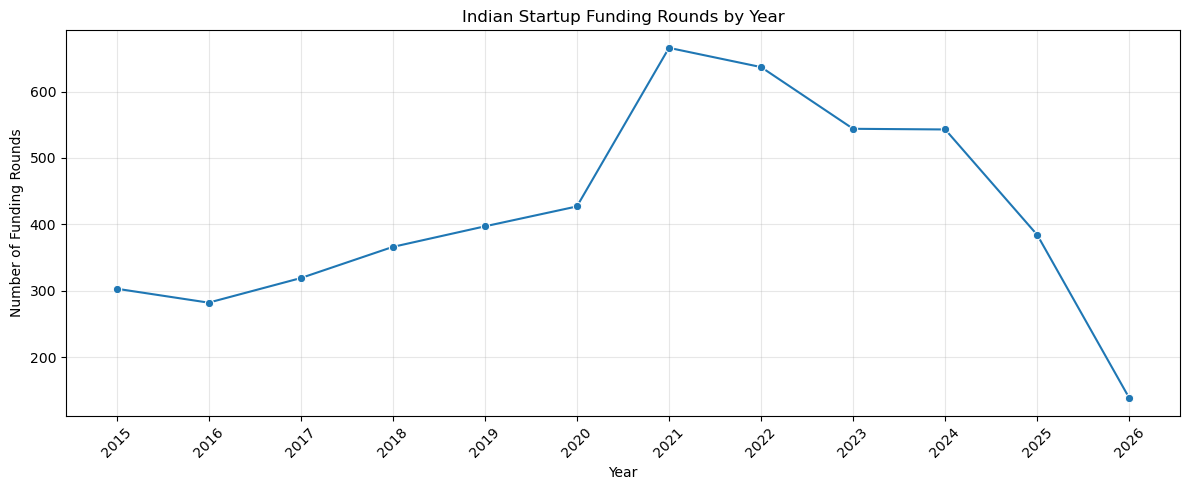

In [3]:

# Count funding rounds by year
yearly_funding = (
    df.groupby("year")
    .size()
    .reset_index(name="funding_rounds")
)

print(yearly_funding)

# Visualize yearly funding activity
plt.figure(figsize=(12, 5))

sns.lineplot(
    data=yearly_funding,
    x="year",
    y="funding_rounds",
    marker="o"
)

plt.title("Indian Startup Funding Rounds by Year")
plt.xlabel("Year")
plt.ylabel("Number of Funding Rounds")
plt.xticks(yearly_funding["year"], rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


Top 10 Startup Sectors:
sector
Consumer                     867
Fintech                      574
Retail                       535
Food and Agriculture Tech    445
Enterprise Applications      336
Healthtech                   312
Edtech                       243
Financial Services           206
Food and Agriculture         183
High Tech                    170
Name: count, dtype: int64


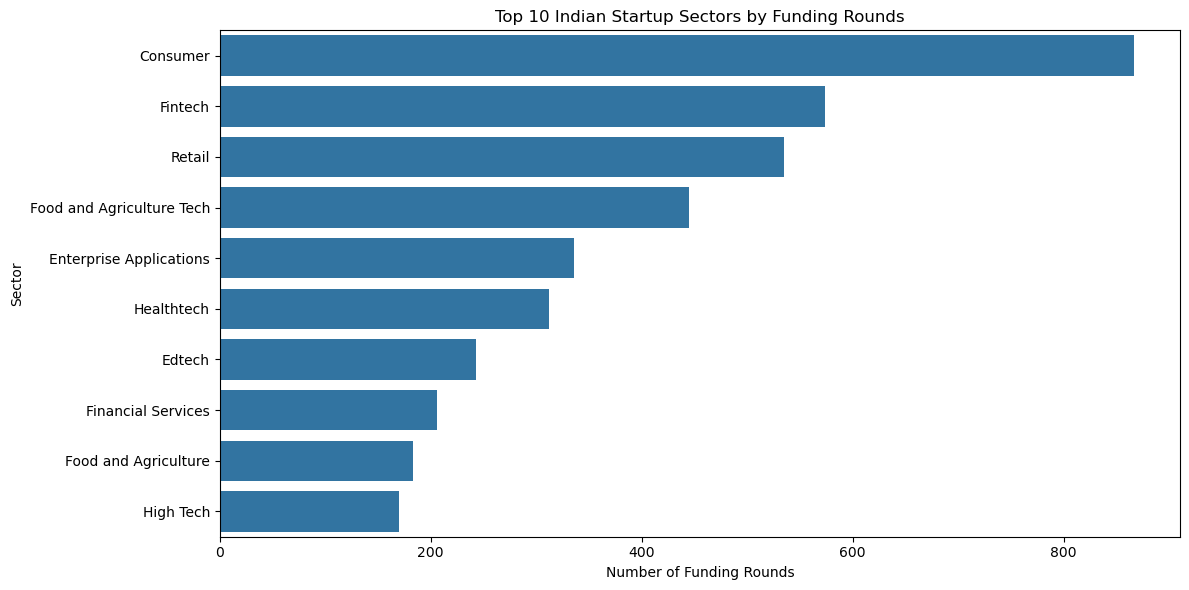

In [4]:

# Count funding rounds by sector
top_sectors = (
    df[df["sector"] != "Unknown"]
    ["sector"]
    .value_counts()
    .head(10)
)

print("Top 10 Startup Sectors:")
print(top_sectors)

# Visualization
plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_sectors.values,
    y=top_sectors.index
)

plt.title("Top 10 Indian Startup Sectors by Funding Rounds")
plt.xlabel("Number of Funding Rounds")
plt.ylabel("Sector")
plt.tight_layout()
plt.show()


Top 10 Startup Cities:
city
Bengaluru    1465
Mumbai        907
New Delhi     673
Gurugram      636
Pune          216
Hyderabad     199
Chennai       170
Noida         155
Ahmedabad     102
Jaipur         81
Name: count, dtype: int64


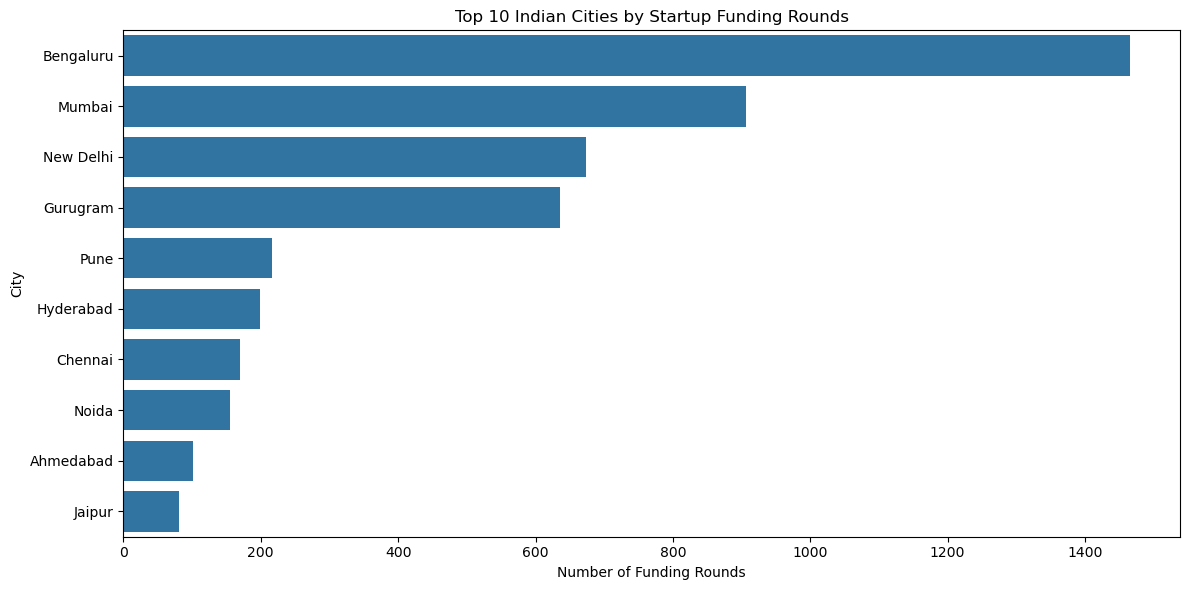

In [5]:

# Count funding rounds by city
top_cities = (
    df[df["city"] != "Unknown"]
    ["city"]
    .value_counts()
    .head(10)
)

print("Top 10 Startup Cities:")
print(top_cities)

# Visualization
plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_cities.values,
    y=top_cities.index
)

plt.title("Top 10 Indian Cities by Startup Funding Rounds")
plt.xlabel("Number of Funding Rounds")
plt.ylabel("City")
plt.tight_layout()
plt.show()


Funding Analysis by Stage:


,funding_rounds,total_funding_usd,average_funding_usd,median_funding_usd
stage,,,,
Undisclosed,1204,4.641181e+10,3.854801e+07,7875000.0
Debt,251,6.776056e+09,2.699624e+07,10000000.0
Series E,42,5.577928e+09,1.328078e+08,66500000.0
Series B,244,5.537483e+09,2.269460e+07,13600000.0
Series D,82,4.742810e+09,5.783915e+07,42000000.0
Series F,19,4.625280e+09,2.434358e+08,150000000.0
Series C,128,4.593966e+09,3.589036e+07,26500000.0
Series A,499,4.222339e+09,8.461601e+06,5500000.0
Strategic,26,2.049288e+09,7.881877e+07,7150000.0


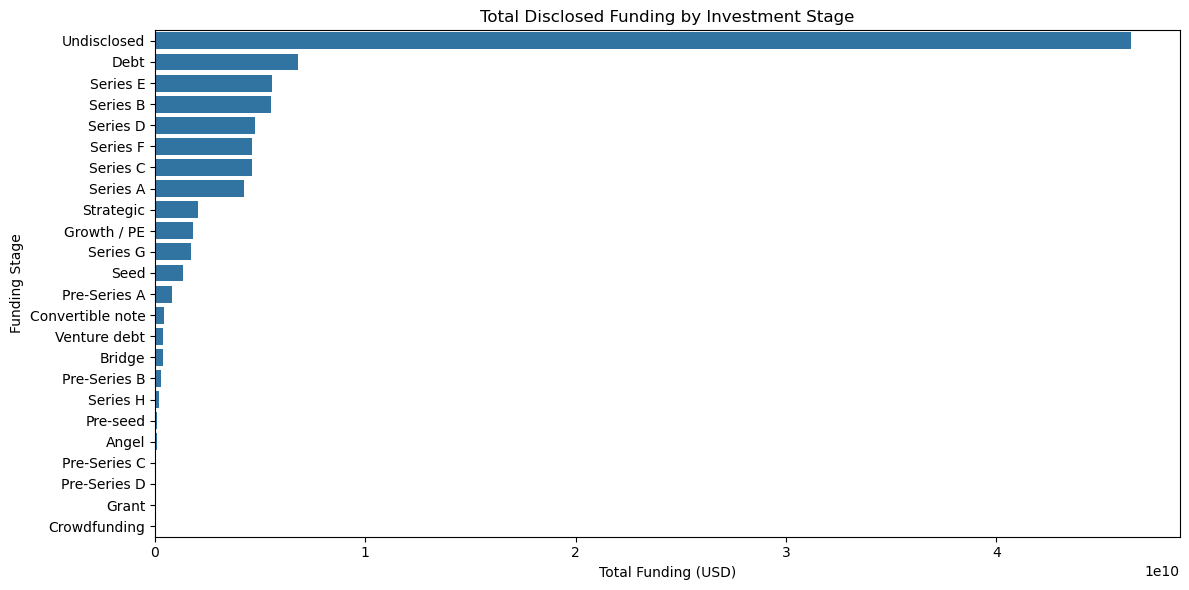

In [6]:

# Filter records with disclosed funding amounts
disclosed_funding = df.dropna(subset=["amount_usd"]).copy()

# Calculate funding statistics by stage
stage_analysis = (
    disclosed_funding
    .groupby("stage")
    .agg(
        funding_rounds=("round_id", "count"),
        total_funding_usd=("amount_usd", "sum"),
        average_funding_usd=("amount_usd", "mean"),
        median_funding_usd=("amount_usd", "median")
    )
    .sort_values("total_funding_usd", ascending=False)
)

print("Funding Analysis by Stage:")
display(stage_analysis)

# Visualization: Total funding by stage
plt.figure(figsize=(12, 6))

sns.barplot(
    data=stage_analysis.reset_index(),
    x="total_funding_usd",
    y="stage"
)

plt.title("Total Disclosed Funding by Investment Stage")
plt.xlabel("Total Funding (USD)")
plt.ylabel("Funding Stage")
plt.tight_layout()
plt.show()


Top 10 Active Investors:
lead_investor
Inflection Point Ventures    66
Venture Catalysts            57
Sequoia Capital              39
Indian Angel Network         38
Blume Ventures               35
Kalaari Capital              33
Innoven Capital              28
Sequoia Capital India        28
Tiger Global                 28
Accel                        27
Name: count, dtype: int64


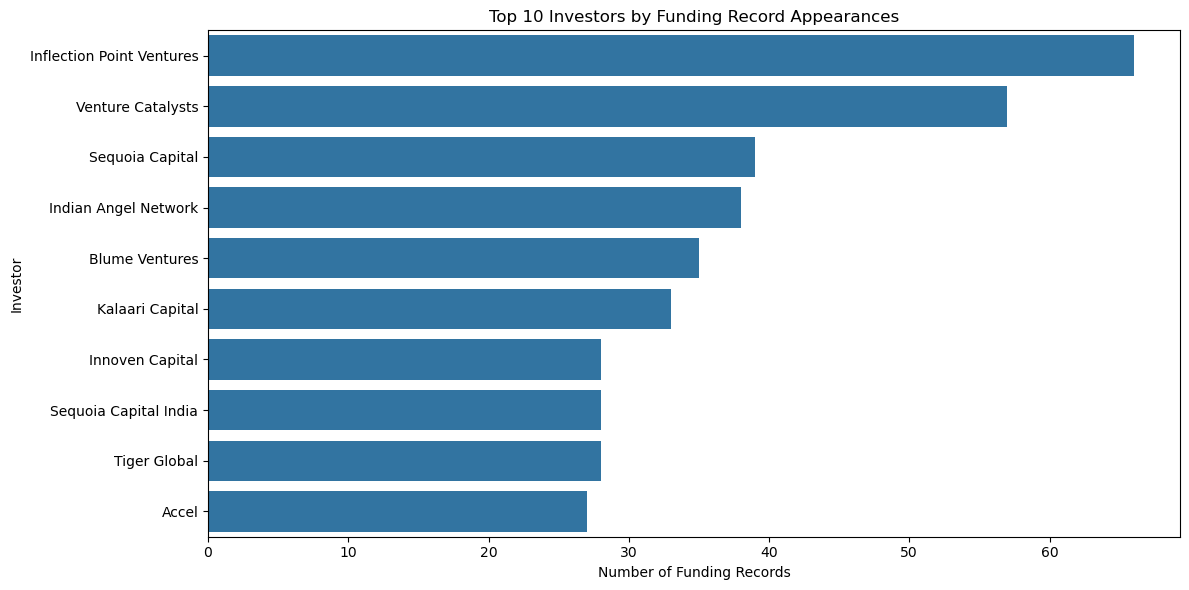

In [7]:

# Exclude unavailable investor names
investor_data = df[
    ~df["lead_investor"].isin(["Unknown", ""])
]

# Count investor appearances
top_investors = (
    investor_data["lead_investor"]
    .value_counts()
    .head(10)
)

print("Top 10 Active Investors:")
print(top_investors)

# Visualization
plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_investors.values,
    y=top_investors.index
)

plt.title("Top 10 Investors by Funding Record Appearances")
plt.xlabel("Number of Funding Records")
plt.ylabel("Investor")
plt.tight_layout()
plt.show()


Correlation Matrix:


,amount_usd,investor_count
amount_usd,1.000000,0.039859
investor_count,0.039859,1.000000


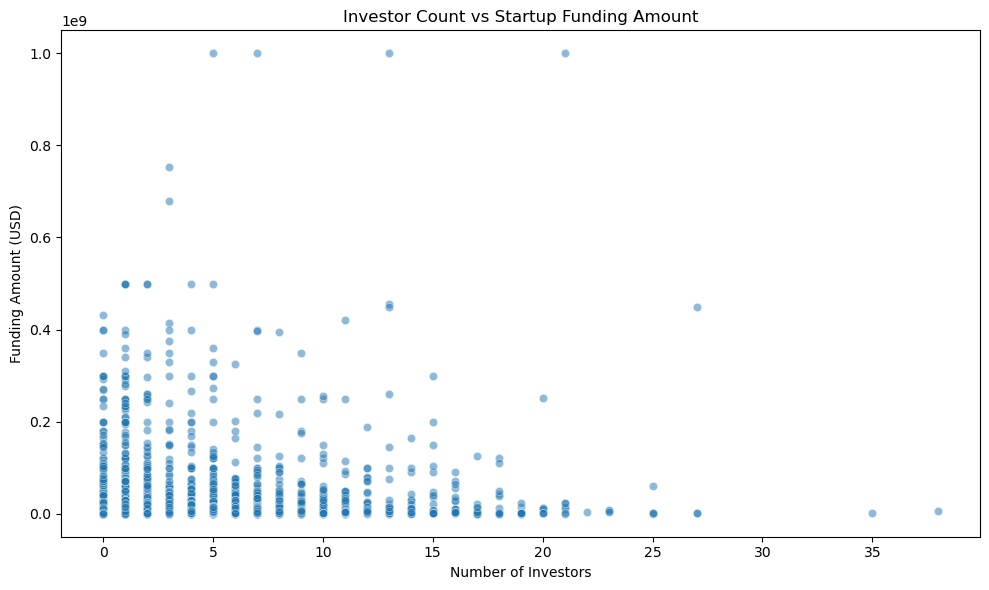

In [8]:

# Select disclosed funding records
investor_funding = df.dropna(
    subset=["amount_usd", "investor_count"]
)

# Correlation calculation
correlation = investor_funding[
    ["amount_usd", "investor_count"]
].corr()

print("Correlation Matrix:")
display(correlation)

# Scatter plot
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=investor_funding,
    x="investor_count",
    y="amount_usd",
    alpha=0.5
)

plt.title("Investor Count vs Startup Funding Amount")
plt.xlabel("Number of Investors")
plt.ylabel("Funding Amount (USD)")
plt.tight_layout()
plt.show()


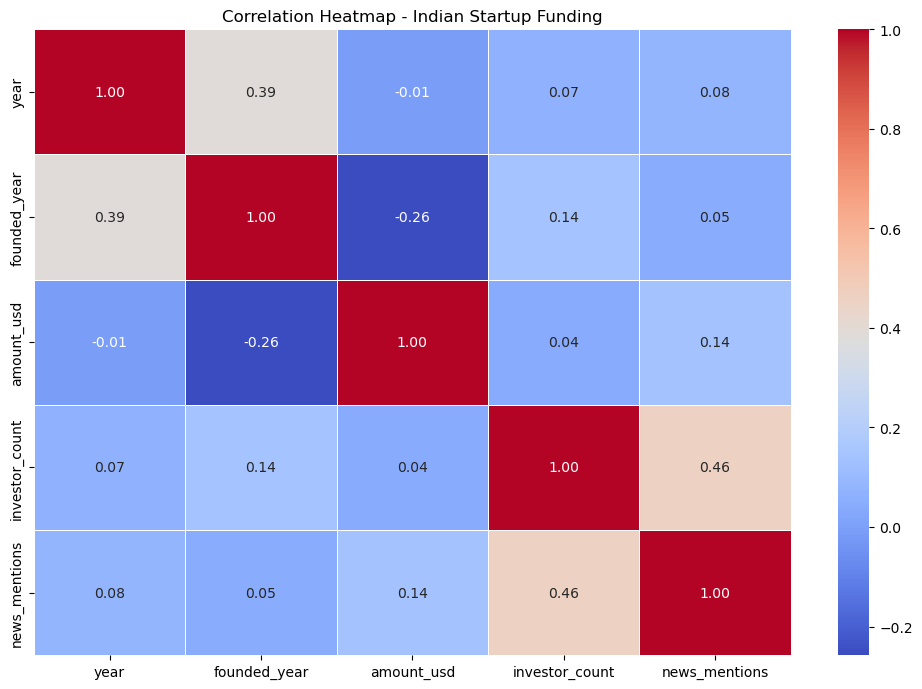

In [9]:

# Select numerical columns
numerical_data = df[
    [
        "year",
        "founded_year",
        "amount_usd",
        "investor_count",
        "news_mentions"
    ]
]

# Calculate correlation
correlation_matrix = numerical_data.corr()

# Visualize correlation
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap - Indian Startup Funding")
plt.tight_layout()
plt.show()


In [10]:
pip install sweetviz

Defaulting to user installation because normal site-packages is not writeable
  Using cached sweetviz-2.3.3-py3-none-any.whl.metadata (22 kB)
Using cached sweetviz-2.3.3-py3-none-any.whl (15.1 MB)
Note: you may need to restart the kernel to use updated packages.


In [11]:

import sweetviz as sv

# Generate automated EDA report
report = sv.analyze(df)

# Save report as HTML
report.show_html(
    "outputs/indian_startup_eda_report.html",
    open_browser=False
)

print("Automated EDA report generated successfully!")


                                             |                                             | [  0%]   00:00 ->…

Report outputs/indian_startup_eda_report.html was generated.
Automated EDA report generated successfully!


In [12]:

from pathlib import Path

# Create output directory
output_dir = Path("outputs")
output_dir.mkdir(exist_ok=True)

# Export analytical summaries
yearly_funding.to_csv(
    output_dir / "yearly_funding_analysis.csv",
    index=False
)

stage_analysis.to_csv(
    output_dir / "funding_stage_analysis.csv"
)

top_sectors.rename_axis("sector").reset_index(
    name="funding_rounds"
).to_csv(
    output_dir / "top_sectors.csv",
    index=False
)

top_cities.rename_axis("city").reset_index(
    name="funding_rounds"
).to_csv(
    output_dir / "top_cities.csv",
    index=False
)

top_investors.rename_axis("investor").reset_index(
    name="appearances"
).to_csv(
    output_dir / "top_investors.csv",
    index=False
)

print("All analytical results exported successfully!")


All analytical results exported successfully!


In [13]:

print("=" * 50)
print("W5D5 PROJECT - FINAL VERIFICATION")
print("=" * 50)

print("Total Funding Records:", len(df))
print("Unique Startups:", df["company_name"].nunique())
print("Unique Sectors:", df["sector"].nunique())
print("Unique Cities:", df["city"].nunique())

print(
    "Disclosed Funding Records:",
    df["amount_usd"].notna().sum()
)

print(
    "Undisclosed Funding Records:",
    df["amount_usd"].isna().sum()
)

print(
    "Total Disclosed Funding (USD):",
    df["amount_usd"].sum()
)

print("=" * 50)
print("EDA ANALYSIS COMPLETED!")
print("=" * 50)


W5D5 PROJECT - FINAL VERIFICATION
Total Funding Records: 5006
Unique Startups: 2163
Unique Sectors: 49
Unique Cities: 128
Disclosed Funding Records: 4031
Undisclosed Funding Records: 975
Total Disclosed Funding (USD): 92107684190.0
EDA ANALYSIS COMPLETED!
